ขั้นตอนที่ 1: การนำเข้าและสำรวจข้อมูล

In [7]:
import pandas as pd
import numpy as np

# 1. โหลดข้อมูลจากไฟล์ HDF5
file_path = 'VNAT_Feature_Dataframe_release_1.h5'
df = pd.read_hdf(file_path, key='/features')

print("จำนวนตัวอย่างทั้งหมด:", len(df))
print("สัดส่วนจำนวนตัวอย่างในแต่ละคลาส (Class Distribution):")
print(df['labels'].value_counts())

display(df.head())

จำนวนตัวอย่างทั้งหมด: 15093
สัดส่วนจำนวนตัวอย่างในแต่ละคลาส (Class Distribution):
labels
CHAT             10498
STREAMING         1826
C2                1675
FILE_TRANSFER      851
VOIP               243
Name: count, dtype: int64


,out_iat_min,out_iat_max,out_iat_mean,out_iat_std_dev,in_iat_min,in_iat_max,in_iat_mean,in_iat_std_dev,flow_iat_min,flow_iat_max,...,out_log_std_dev_detail_coeffs_4,out_log_std_dev_detail_coeffs_5,out_log_std_dev_detail_coeffs_6,out_log_std_dev_detail_coeffs_7,out_log_std_dev_detail_coeffs_8,out_log_std_dev_detail_coeffs_9,out_log_std_dev_detail_coeffs_10,out_log_std_dev_detail_coeffs_11,out_log_std_dev_detail_coeffs_12,labels
0,0.000024,15.646865,0.891706,3.579154,0.000054,15.607829,0.842655,3.480432,0.000024,15.607655,...,0.958770,1.279343,1.569488,1.790519,2.070103,2.096996,2.428894,2.759263,2.904293,C2
1,0.001351,10.258183,3.232542,2.992364,0.018239,10.202419,1.941929,2.765867,0.000105,10.202419,...,0.251599,0.637307,1.005774,1.309230,1.554615,1.820888,2.220975,2.554422,2.914594,CHAT
2,0.028768,4.019976,1.227752,1.278413,0.026368,3.980284,1.123653,1.264388,0.001719,3.978565,...,0.014055,0.420507,0.762716,1.109513,1.471456,1.754881,2.001594,2.351996,2.736217,CHAT
3,0.030268,3.264299,1.456833,1.292042,0.029519,3.226012,1.458189,1.291581,0.001323,3.224246,...,0.023604,0.542705,0.945885,1.278526,1.571150,1.862637,2.113894,2.454169,2.844140,CHAT
4,0.025157,3.391598,1.068763,1.193896,0.028530,3.332177,1.131416,1.185435,0.001574,3.329872,...,0.155742,0.459030,0.914504,1.178986,1.553150,1.858731,2.111992,2.449052,2.836318,CHAT


ขั้นตอนที่ 2: การเตรียมข้อมูลและแบ่งชุดข้อมูล

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# 2.1 ลบแถวข้อมูลที่ซ้ำกัน (Deduplication) เพื่อป้องกัน Data Leakage ระหว่างชุดข้อมูล
df = df.drop_duplicates().reset_index(drop=True)    
print(f"ขนาดข้อมูลหลังลบแถวซ้ำ: {len(df)} แถว\n")

# 2.2 แยก X (ฟีเจอร์) และ y (เป้าหมาย)
X = df.drop(columns=['labels']).copy()
y = df['labels'].copy()

# 2.3 จัดการค่า Inf -> NaN
X = X.replace([np.inf, -np.inf], np.nan)

# 2.4 แปลง Label ตัวหนังสือเป็นตัวเลข
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 2.5 แบ่งข้อมูล 3 ชุด: Train 70%, Val 15%, Test 15% (แบบ Stratified)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.30, stratify=y_encoded, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# 2.6 Impute (เติมค่าว่างด้วย Median) โดย fit เฉพาะ X_train เท่านั้น (ไม่ต้องทำการ Scale ข้อมูล)
imputer = SimpleImputer(strategy='median')
X_train_clean = imputer.fit_transform(X_train)
X_val_clean = imputer.transform(X_val)
X_test_clean = imputer.transform(X_test)

feature_names = X.columns.tolist()

print("--- สรุปจำนวนข้อมูลทั้ง 3 ชุด ---")
print(f"Train Set (70%):      {X_train_clean.shape[0]} ตัวอย่าง")
print(f"Validation Set (15%): {X_val_clean.shape[0]} ตัวอย่าง")
print(f"Test Set (15%):       {X_test_clean.shape[0]} ตัวอย่าง")

ขนาดข้อมูลหลังลบแถวซ้ำ: 14896 แถว

--- สรุปจำนวนข้อมูลทั้ง 3 ชุด ---
Train Set (70%):      10427 ตัวอย่าง
Validation Set (15%): 2234 ตัวอย่าง
Test Set (15%):       2235 ตัวอย่าง


ขั้นตอนที่ 3: การฝึกสอนและตรวจสอบการเรียนรู้

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score

# 1. กำหนดช่วง Hyperparameters ที่ต้องการทดลอง
param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

# 2. ใช้ Validation ค้นหา Hyperparameters ที่ดีที่สุดอัตโนมัติ 
print("กำลังค้นหา Hyperparameters ที่ดีที่สุดด้วย Validation...")
base_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=10,             
    scoring='f1_macro',    # เน้นประสิทธิภาพ Macro F1
    cv=3,
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train_clean, y_train)

# 3. ดึงโมเดลที่ดีที่สุดมาใช้งาน
rf_model = rf_search.best_estimator_
print(f"ค่า Hyperparameters ที่ดีที่สุด:{rf_search.best_params_}\n")

# 4. ประเมินสุขภาพโมเดล (Train vs Validation Set)
y_train_pred = rf_model.predict(X_train_clean)
y_val_pred = rf_model.predict(X_val_clean)

train_acc = accuracy_score(y_train, y_train_pred) * 100
val_acc = accuracy_score(y_val, y_val_pred) * 100

train_f1 = f1_score(y_train, y_train_pred, average='macro')
val_f1 = f1_score(y_val, y_val_pred, average='macro')

f1_diff = train_f1 - val_f1
acc_diff = train_acc - val_acc

print("=== ผลการประเมินสุขภาพโมเดลหลัง Tuning (Model Health Check) ===")
print(f"Train Accuracy:      {train_acc:.2f}% | Train Macro F1:      {train_f1:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}% | Validation Macro F1: {val_f1:.4f}")
print(f"• ความแตกต่าง Macro F1: {f1_diff:.4f}")
print(f"• ความแตกต่าง Accuracy: {acc_diff:.2f}%\n")

if f1_diff < 0.03 and acc_diff < 3.0:
    print("สรุป: โมเดลเรียนรู้ได้ดีเยี่ยม มี Generalization สูง และไม่เกิด Overfitting")
elif f1_diff < 0.08:
    print("สรุป: โมเดลมี Overfitting เล็กน้อย แต่อยู่ในเกณฑ์ยอมรับได้")
else:
    print("สรุป: โมเดลเริ่มมีปัญหา Overfitting ควรปรับลด max_depth ลงอีก")

กำลังค้นหา Hyperparameters ที่ดีที่สุดด้วย Validation...
ค่า Hyperparameters ที่ดีที่สุด:{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 15, 'class_weight': 'balanced_subsample'}

=== ผลการประเมินสุขภาพโมเดลหลัง Tuning (Model Health Check) ===
Train Accuracy:      99.99% | Train Macro F1:      0.9999
Validation Accuracy: 99.55% | Validation Macro F1: 0.9931
• ความแตกต่าง Macro F1: 0.0068
• ความแตกต่าง Accuracy: 0.44%

สรุป: โมเดลเรียนรู้ได้ดีเยี่ยม มี Generalization สูง และไม่เกิด Overfitting


ขั้นตอนที่ 4: การประเมินผลโมเดลบนชุดข้อมูลทดสอบ

In [10]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. ทำนายผลบน Test Set
y_test_pred = rf_model.predict(X_test_clean)

# 2. สร้าง DataFrame จาก Classification Report
report_dict = classification_report(
    y_test, y_test_pred, 
    target_names=label_encoder.classes_, 
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()

per_class_df = report_df.drop(index=['accuracy', 'macro avg', 'weighted avg'])

print("--- ตารางประเมินผลแยกตามประเภททราฟฟิก (Per-Class Evaluation) ---")
display(per_class_df.style.background_gradient(cmap='Blues', subset=['f1-score']))

# 4. คำนวณค่า 3 บรรทัดล่าง และนำมาเขียนสรุปด้านล่างแทน
test_acc = accuracy_score(y_test, y_test_pred) * 100
macro_f1 = f1_score(y_test, y_test_pred, average='macro')
weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')

print("=" * 60)
print("📌 สรุปภาพรวมประสิทธิภาพของโมเดล (Overall Performance Summary)")
print("=" * 60)
print(f"• Accuracy (ความถูกต้องภาพรวม):  {test_acc:.2f}%")
print(f"• Macro Avg F1-Score:           {macro_f1:.4f}")
print(f"• Weighted Avg F1-Score:        {weighted_f1:.4f}")

--- ตารางประเมินผลแยกตามประเภททราฟฟิก (Per-Class Evaluation) ---


,precision,recall,f1-score,support
C2,0.988142,0.992063,0.990099,252.000000
CHAT,1.000000,0.997411,0.998704,1545.000000
FILE_TRANSFER,0.983871,0.953125,0.968254,128.000000
STREAMING,0.967972,0.992701,0.980180,274.000000
VOIP,1.000000,1.000000,1.000000,36.000000


📌 สรุปภาพรวมประสิทธิภาพของโมเดล (Overall Performance Summary)
• Accuracy (ความถูกต้องภาพรวม):  99.37%
• Macro Avg F1-Score:           0.9874
• Weighted Avg F1-Score:        0.9937


ขั้นตอนที่ 5: การวิเคราะห์ข้อมูล

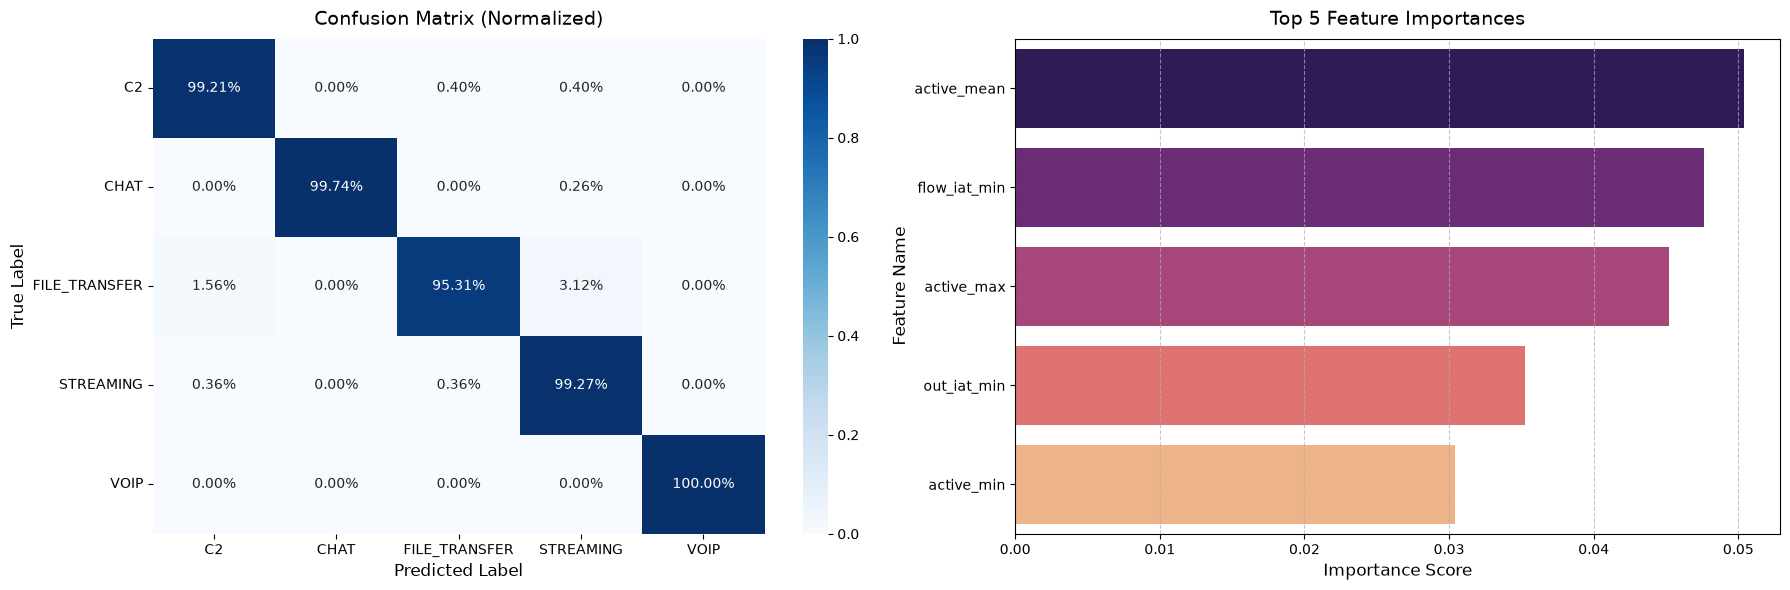

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. เตรียมข้อมูล Confusion Matrix (แบบ Normalized %)
cm_norm = confusion_matrix(y_test, y_test_pred, normalize='true')

# 2. เตรียมข้อมูล Feature Importance (เลือกเฉพาะ Top 10)
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

top_5_features = feature_imp_df.head(5)

# 3. พล็อตทั้ง 2 รูปเคียงข้างกันในแนวซ้าย-ขวา
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# --- รูปซ้าย: Confusion Matrix ---
sns.heatmap(
    cm_norm, annot=True, fmt='.2%', cmap='Blues', 
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_, 
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix (Normalized)', fontsize=14, pad=10)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# --- รูปขวา: Top 5 Feature Importance (เพิ่ม hue และ legend=False เพื่อปิด Warning) ---
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=top_5_features, 
    hue='Feature',       
    legend=False,        
    palette='magma', 
    ax=axes[1]
)
axes[1].set_title('Top 5 Feature Importances', fontsize=14, pad=10)
axes[1].set_xlabel('Importance Score', fontsize=12)
axes[1].set_ylabel('Feature Name', fontsize=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

ขั้นตอนที่ 6: การบันทึกและส่งออกโมเดลเพื่อนำไปทดสอบ

In [12]:
import joblib
import pandas as pd
import numpy as np

# 1. บันทึก Artifacts
joblib.dump(rf_model, 'rf_model.joblib')
joblib.dump(imputer, 'imputer.joblib')
joblib.dump(label_encoder, 'label_encoder.joblib')
joblib.dump(feature_names, 'feature_names.joblib')

# 2. ดึงข้อมูลดิบจาก Index ของ X_test
if 'X_test' in locals() and hasattr(X_test, 'index'):
    raw_test_data = df.loc[X_test.index]
else:
    raw_test_data = df

target_col = 'labels' if 'labels' in raw_test_data.columns else 'label'

# 3. สุ่มคลาสละ 10 ตัวอย่าง
sample_list = []
for label_val, group in raw_test_data.groupby(target_col):
    n_samples = min(10, len(group))
    sample_list.append(group.sample(n=n_samples, random_state=42))

sample_per_class = pd.concat(sample_list, axis=0).reset_index(drop=True)

# บันทึกไฟล์
sample_per_class.to_csv('sample_data_with_labels.csv', index=False)

print(f"✅ บันทึกไฟล์ sample_data_with_labels.csv สำเร็จ! ({len(sample_per_class)} รายการ)")

PermissionError: [Errno 13] Permission denied: 'sample_data_with_labels.csv'